# Assignment #3

# 1. K-means from scratch (50 points)

Code up the K-means algorithm. To test your code, sample from the three bivariate Gaussian distributions provided below and find three clusters from this sampled data. To initialize your algorihtm, you may use the initial centroids defined below. After predicting the cluster to which each data point belongs, make a scatter plot similar to the one shown below. For consistency, set the random seed to 1 before sampling from the three bivariate Gaussian distributions.

* Bivariate Gaussians
$$\mathbf{\mu_1} = \begin{bmatrix}
3.0\\
1.0\\
\end{bmatrix}$$

$$\mathbf{\mu_2} = \begin{bmatrix}
-1.0\\
3.0\\
\end{bmatrix}$$

$$\mathbf{\mu_2} = \begin{bmatrix}
-5.0\\
2.0\\
\end{bmatrix}$$

$$\mathbf{\Sigma_1} = \mathbf{\Sigma_2} = \mathbf{\Sigma_3}\begin{bmatrix}
0.9&0.3\\
0.3&0.9\\
\end{bmatrix}$$

* Initial centroids:
$$\mathbf{c_1} = \begin{bmatrix}
0.4\\
0.3\\
\end{bmatrix}$$

$$\mathbf{c_2} = \begin{bmatrix}
0.1\\
0.4\\
\end{bmatrix}$$

$$\mathbf{c_2} = \begin{bmatrix}
-2.0\\
2.0\\
\end{bmatrix}$$

Final Centroids:
[[ 2.824456    0.84653064]
 [-1.02173212  3.11381515]
 [-5.17750158  2.033979  ]]

Number of Iterations: 6


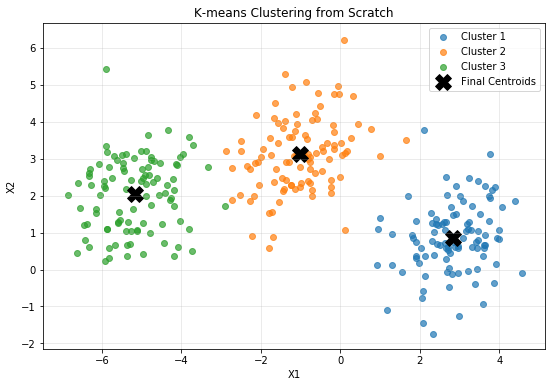

In [30]:
import numpy as np
import matplotlib.pyplot as plt

# --------------------------------------------------
# Part 1: Generate Sample Data
# --------------------------------------------------

# Set random seed
np.random.seed(1)

# Define means
mu1 = np.array([3.0, 1.0])
mu2 = np.array([-1.0, 3.0])
mu3 = np.array([-5.0, 2.0])

# Define covariance matrix
cov = np.array([
    [0.9, 0.3],
    [0.3, 0.9]
])

# Number of samples per distribution
n_samples = 100

# Generate samples from three bivariate Gaussian distributions
X1 = np.random.multivariate_normal(mu1, cov, n_samples)
X2 = np.random.multivariate_normal(mu2, cov, n_samples)
X3 = np.random.multivariate_normal(mu3, cov, n_samples)

# Combine datasets
X = np.vstack((X1, X2, X3))


# --------------------------------------------------
# Part 2: Define Initial Centroids
# --------------------------------------------------

centroids = np.array([
    [0.4, 0.3],
    [0.1, 0.4],
    [-2.0, 2.0]
])


# --------------------------------------------------
# Part 3: Implement K-means from Scratch
# --------------------------------------------------

def kmeans(X, centroids, max_iterations=100, tolerance=1e-6):

    for iteration in range(max_iterations):

        # Calculate distances between data points and centroids
        distances = np.linalg.norm(
            X[:, np.newaxis] - centroids,
            axis=2
        )

        # Assign each point to its closest centroid
        labels = np.argmin(distances, axis=1)

        # Update centroids using the mean of assigned points
        new_centroids = np.array([
            X[labels == k].mean(axis=0)
            for k in range(len(centroids))
        ])

        # Check for convergence
        if np.linalg.norm(new_centroids - centroids) < tolerance:
            centroids = new_centroids
            break

        centroids = new_centroids

    return labels, centroids, iteration + 1


# --------------------------------------------------
# Part 4: Run K-means
# --------------------------------------------------

labels, final_centroids, iterations = kmeans(X, centroids)

print("Final Centroids:")
print(final_centroids)

print("\nNumber of Iterations:", iterations)


# --------------------------------------------------
# Part 5: Visualize Clusters
# --------------------------------------------------

plt.figure(figsize=(9, 6))

# Plot each cluster
for k in range(3):
    plt.scatter(
        X[labels == k, 0],
        X[labels == k, 1],
        label=f"Cluster {k + 1}",
        alpha=0.7
    )

# Plot final centroids
plt.scatter(
    final_centroids[:, 0],
    final_centroids[:, 1],
    marker='X',
    s=250,
    color='black',
    label='Final Centroids'
)

# Add plot labels and formatting
plt.title("K-means Clustering from Scratch")
plt.xlabel("X1")
plt.ylabel("X2")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 2. Predicting soil taxonomy (50 pts)

In the United States, soils are classified using the [USDA soil taxonomy](https://www.nrcs.usda.gov/Internet/FSE_DOCUMENTS/nrcs142p2_051232.pdf). Within the USDA soil taxonomy, the most general level is the taxonomic order. In this problem we will be using a suite of decision-tree based classification algorithms to create spatial maps of taxonomic order over western Illinois. The point observations come from the [NASIS database](https://www.nrcs.usda.gov/wps/portal/nrcs/detail/soils/survey/tools/?cid=nrcs142p2_053552) while the environmental predictors come from Sentinel 2, the National Elevation Data, and the National Land Cover database.

All the data has already been subsetted and preprocessed and are compiled in the following NetCDF file `/data/HW/HW3.nc`. The file is split into two groups: predictors and observations. The predictors group contains a set of 1 arcsec maps for the domain and the observations group contains the in-situ taxonomic order observations with their associated geographic coordinates. Although not required, we recommend using xarray to read in these data. 

**A.** Read in and create maps of all the predictors. Describe any apparent discrepancies in spatial resolution between the maps.

**B.** Read in the in-situ observations and assemble the corresponding predictors for each site. Create the $\mathbf{X}$ array of predictors and the $\mathbf{y}$ array of observed taxonomic orders. Note that you will need to convert the taxonomic order names to integers.

**C.** Use the validation set approach to divide your data into training and test datasets. The training dataset should 20% of the data. Then fit a Decision tree using the training data and evaluate its accuracy for both the training and test datasets. Explain the differences in accuracy when evaluating the training and test datasets. To ensure reproduceability, when initializing the decision tree, set the random_state to 1.

**D.** Using  all the site data, perform a 10-fold cross validation of the decision tree and compare the results to the previous exercise. Set random_state to 1 and set shuffle to True.

**E.** Setting the number of decision trees to 100, perform a 10-fold cross validation using Bagging, Random Forests, Gradient Boosting, and Multilayer Perceptrons (ANNs). Discuss how the results of these different ensemble methods vary amongst themselves. Also compare the results to those obtained from a single decision tree. Remember to set random_state to 1.

**F.** Using 100 trees, fit a Random Forest to the entire sites dataset and report the out of bag score. Compare that result to that obtained from the cross validation. Explain what the out of bag score is and how it can be more useful than cross validation. Remember to set random_state to 1.

**G.** Starting from 10 to 100 decision trees per Random Forest, determine the optimal number of decision trees. 

**H.** After fitting a random forest with 100 trees, plot a map of the entire region of the predicted taxonomy order.

**I.** Use Principal Component Analysis (PCA) to determine a reduced number of covariates. The exact number of features that you use from PCA is not as important as much as explaining why you use the result that you use. Fit and evaluate the Random Forest fit from the corresponding principal components.

In [18]:
import netCDF4 as nc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    BaggingClassifier,
    RandomForestClassifier,
    GradientBoostingClassifier
)
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Open the NetCDF dataset
data = '/data/HW/HW3.nc'
rootgrp = nc.Dataset(data, 'r')

# Access the predictor and observation groups
predictors = rootgrp.groups['predictors']
observations = rootgrp.groups['observations']

# Predictor variable names
predictor_names = [
    'elevation',
    'ndvi',
    'evi',
    'red',
    'green',
    'blue',
    'tree_cover_fraction',
    'gamma_uranium',
    'gamma_thorium',
    'gamma_potassium'
]

print("Dataset successfully opened.")
print("Predictor variables:", predictor_names)

Dataset successfully opened.
Predictor variables: ['elevation', 'ndvi', 'evi', 'red', 'green', 'blue', 'tree_cover_fraction', 'gamma_uranium', 'gamma_thorium', 'gamma_potassium']


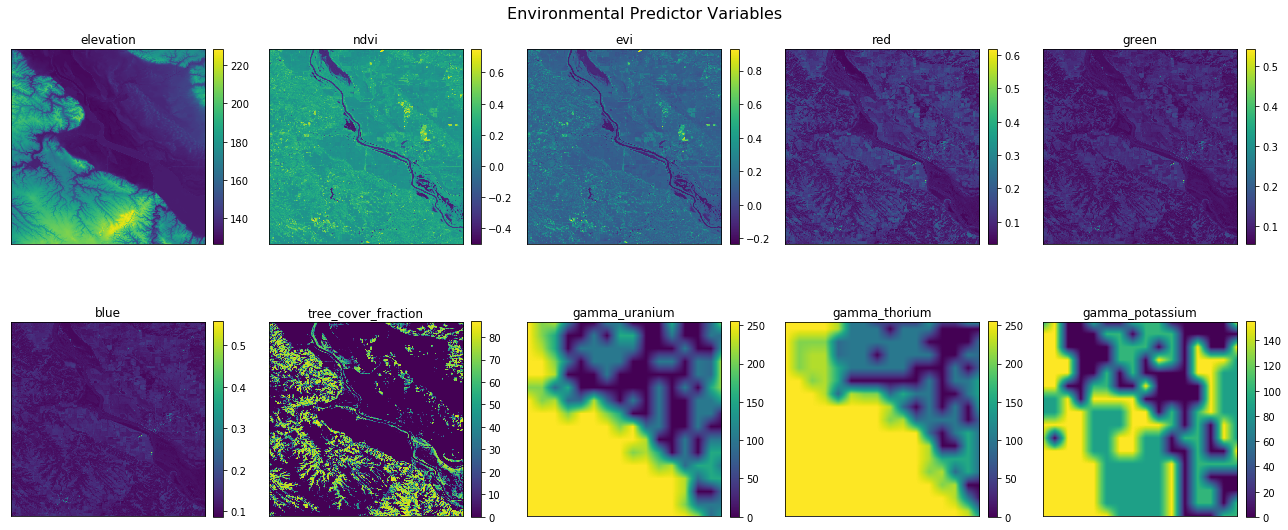

Latitude spacing:
Minimum: 0.00027751256718744344
Maximum: 0.00027751256719454886
Mean: 0.00027751256719184893

Longitude spacing:
Minimum: 0.000277512567180338
Maximum: 0.00027751256719454886
Mean: 0.00027751256719184893

Raster dimensions:
Latitude: 1080
Longitude: 1080


In [19]:
# PART A

fig, axes = plt.subplots(2, 5, figsize=(18, 8))

for i, name in enumerate(predictor_names):

    raster = predictors.variables[name][:]

    # Convert masked values to NaN
    raster = np.ma.filled(raster, np.nan)

    ax = axes.flatten()[i]

    image = ax.imshow(
        raster,
        cmap='viridis'
    )

    ax.set_title(name)
    ax.set_xticks([])
    ax.set_yticks([])

    plt.colorbar(image, ax=ax, fraction=0.046, pad=0.04)

plt.suptitle('Environmental Predictor Variables', fontsize=16)
plt.tight_layout()
plt.show()

lat = predictors.variables['lat'][:]
lon = predictors.variables['lon'][:]

lat_spacing = np.abs(np.diff(lat))
lon_spacing = np.abs(np.diff(lon))

print("Latitude spacing:")
print("Minimum:", np.min(lat_spacing))
print("Maximum:", np.max(lat_spacing))
print("Mean:", np.mean(lat_spacing))

print("\nLongitude spacing:")
print("Minimum:", np.min(lon_spacing))
print("Maximum:", np.max(lon_spacing))
print("Mean:", np.mean(lon_spacing))

print("\nRaster dimensions:")
print("Latitude:", len(lat))
print("Longitude:", len(lon))

In part A, it appears that the gamma values for uranium, thorium, and potassium have a significantly lower spatial resolution than the rest of the predictors

In [20]:
# PART B

# Extract observation coordinates
obs_lat = observations.variables['lat'][:]
obs_lon = observations.variables['lon'][:]

# Extract observed soil taxonomy orders
soil_orders = observations.variables['taxonomic_order'][:]

print("Number of observations:", len(obs_lat))
print("Number of soil taxonomy labels:", len(soil_orders))

# Store extracted predictor values
extracted_data = []

for i in range(len(obs_lat)):

    # Find nearest latitude and longitude indices
    lat_idx = np.argmin(np.abs(lat - obs_lat[i]))
    lon_idx = np.argmin(np.abs(lon - obs_lon[i]))

    # Extract all predictor values at this location
    row = []

    for name in predictor_names:

        raster = predictors.variables[name][:]

        value = raster[lat_idx, lon_idx]

        # Convert masked values to NaN
        if np.ma.is_masked(value):
            value = np.nan

        row.append(value)

    extracted_data.append(row)

# Convert extracted values into a DataFrame
X_df = pd.DataFrame(
    extracted_data,
    columns=predictor_names
)

print("Extracted predictor data:")
print(X_df.head())

# Convert taxonomy labels into strings
soil_orders = np.array([
    str(label.decode('utf-8') if isinstance(label, bytes) else label).strip()
    for label in soil_orders
])

# Encode categorical soil taxonomy labels
label_encoder = LabelEncoder()

y = label_encoder.fit_transform(soil_orders)

# Convert predictor DataFrame into a NumPy array
X = X_df.values.astype(float)

# Remove observations with missing predictor values, if any
valid_rows = np.isfinite(X).all(axis=1)

X = X[valid_rows]
y = y[valid_rows]

print("Predictor matrix (X) shape:", X.shape)
print("Taxonomy array (y) shape:", y.shape)

print("\nPredictor columns:")
print(predictor_names)

print("\nTaxonomy mapping:")

for i, label in enumerate(label_encoder.classes_):
    print(label, "=", i)

print("\nNumber of valid observations:", len(y))

Number of observations: 153
Number of soil taxonomy labels: 153
Extracted predictor data:
    elevation      ndvi       evi       red    green      blue  \
0  145.403854  0.226848  0.171230  0.105400  0.09720  0.119550   
1  130.392471  0.115701  0.077655  0.099550  0.09495  0.117900   
2  133.486664  0.176419  0.134684  0.118225  0.10615  0.125075   
3  144.911652  0.175030  0.151285  0.154950  0.12875  0.141850   
4  163.845093  0.287447  0.217640  0.099125  0.09120  0.114025   

   tree_cover_fraction  gamma_uranium  gamma_thorium  gamma_potassium  
0                 11.0           87.0           21.0             95.0  
1                  0.0          128.0          255.0             10.0  
2                  0.0          102.0           43.0             99.0  
3                  0.0          177.0          244.0             55.0  
4                  7.0           96.0          217.0              8.0  
Predictor matrix (X) shape: (153, 10)
Taxonomy array (y) shape: (153,)

Predictor

In [21]:
# PART C

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    train_size=0.20,
    random_state=1
)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

# Create Decision Tree classifier
tree = DecisionTreeClassifier(random_state=1)

# Train the model
tree.fit(X_train, y_train)

# Generate predictions
y_train_pred = tree.predict(X_train)
y_test_pred = tree.predict(X_test)

# Calculate accuracy
train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

print("\nTraining Accuracy:", train_accuracy)
print("Testing Accuracy:", test_accuracy)

# Calculate confusion matrix
cm = confusion_matrix(y_test, y_test_pred)

print("Confusion Matrix:")
print(cm)

# Classification report
print("\nClassification Report:")

print(classification_report(
    y_test,
    y_test_pred,
    target_names=label_encoder.classes_
))

Training observations: 30
Testing observations: 123

Training Accuracy: 1.0
Testing Accuracy: 0.6178861788617886
Confusion Matrix:
[[30  3  2  7]
 [ 4  5  4  8]
 [ 0  1  8  0]
 [ 2 10  6 33]]

Classification Report:
              precision    recall  f1-score   support

    alfisols       0.83      0.71      0.77        42
    entisols       0.26      0.24      0.25        21
 inceptisols       0.40      0.89      0.55         9
   mollisols       0.69      0.65      0.67        51

    accuracy                           0.62       123
   macro avg       0.55      0.62      0.56       123
weighted avg       0.64      0.62      0.62       123



In part C, the training dataset was evidently not enough to prepare the model for classification, as it only had a 61% success rate on the testing data, and performed particularly badly when trying to classify entisols.

In [22]:
# Part D

# Set up 10-fold cross-validation
kf = KFold(
    n_splits=10,
    shuffle=True,
    random_state=1
)

# Create Decision Tree classifier
tree = DecisionTreeClassifier(random_state=1)

# Perform cross-validation
scores = cross_val_score(
    tree,
    X,
    y,
    cv=kf,
    scoring='accuracy'
)

# Print individual fold accuracies
print("Individual Fold Accuracies:")

for i, score in enumerate(scores):
    print("Fold {}: {:.4f}".format(i + 1, score))

# Calculate mean and standard deviation
mean_accuracy = np.mean(scores)
std_accuracy = np.std(scores)

print("\nMean Cross-Validation Accuracy:", mean_accuracy)
print("Standard Deviation:", std_accuracy)

Individual Fold Accuracies:
Fold 1: 0.8125
Fold 2: 0.6250
Fold 3: 0.5625
Fold 4: 0.6000
Fold 5: 0.9333
Fold 6: 0.4667
Fold 7: 0.6000
Fold 8: 0.4667
Fold 9: 0.7333
Fold 10: 0.7333

Mean Cross-Validation Accuracy: 0.6533333333333333
Standard Deviation: 0.1417622226750758


The mean accuracy of all the folds together is better than the result from part C

In [23]:
# PART E

# Bagging: 100 decision trees
bagging = BaggingClassifier(
    base_estimator=DecisionTreeClassifier(),
    n_estimators=100,
    random_state=1
)

# Random Forest: 100 trees
random_forest = RandomForestClassifier(
    n_estimators=100,
    random_state=1
)

# Gradient Boosting: 100 boosting stages
gradient_boosting = GradientBoostingClassifier(
    n_estimators=100,
    random_state=1
)

# MLP: one hidden layer with 100 neurons
# Standardize predictors before fitting the neural network
mlp = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', MLPClassifier(
        hidden_layer_sizes=(100,),
        max_iter=1000,
        random_state=1
    ))
])

# Store models in a dictionary
models = {
    'Bagging': bagging,
    'Random Forest': random_forest,
    'Gradient Boosting': gradient_boosting,
    'MLP': mlp
}

print("Models successfully defined.")

# Store results
results = {}

for name, model in models.items():

    scores = cross_val_score(
        model,
        X,
        y,
        cv=kf,
        scoring='accuracy'
    )

    mean_accuracy = np.mean(scores)
    std_accuracy = np.std(scores)

    results[name] = (mean_accuracy, std_accuracy)

    print("\n", name)
    print("----------------------------")

    for i, score in enumerate(scores):
        print("Fold {}: {:.4f}".format(i + 1, score))

    print("Mean Accuracy: {:.4f}".format(mean_accuracy))
    print("Standard Deviation: {:.4f}".format(std_accuracy))
    
    print("FINAL MODEL COMPARISON")
print("======================================")

print("{:<22} {:<18} {:<18}".format(
    "Model",
    "Mean Accuracy",
    "Std. Deviation"
))

for name, (mean, std) in results.items():

    print("{:<22} {:<18.4f} {:<18.4f}".format(
        name,
        mean,
        std
    ))

print("\nDecision Tree from Part D:")
print("Mean Accuracy: 0.6533")
print("Std. Deviation: 0.1418")

Models successfully defined.

 Bagging
----------------------------
Fold 1: 0.8125
Fold 2: 0.6250
Fold 3: 0.5625
Fold 4: 0.8667
Fold 5: 0.8667
Fold 6: 0.6667
Fold 7: 0.8667
Fold 8: 0.4667
Fold 9: 0.8000
Fold 10: 0.7333
Mean Accuracy: 0.7267
Standard Deviation: 0.1342
FINAL MODEL COMPARISON

 Random Forest
----------------------------
Fold 1: 0.8125
Fold 2: 0.6250
Fold 3: 0.6250
Fold 4: 0.9333
Fold 5: 0.8667
Fold 6: 0.6667
Fold 7: 0.8667
Fold 8: 0.6000
Fold 9: 0.8667
Fold 10: 0.7333
Mean Accuracy: 0.7596
Standard Deviation: 0.1176
FINAL MODEL COMPARISON

 Gradient Boosting
----------------------------
Fold 1: 0.8750
Fold 2: 0.5625
Fold 3: 0.6250
Fold 4: 0.8000
Fold 5: 0.8667
Fold 6: 0.7333
Fold 7: 0.8667
Fold 8: 0.4667
Fold 9: 0.8667
Fold 10: 0.6667
Mean Accuracy: 0.7329
Standard Deviation: 0.1394
FINAL MODEL COMPARISON


/opt/conda/lib/python3.7/site-packages/sklearn/neural_network/multilayer_perceptron.py:566: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  % self.max_iter, ConvergenceWarning)
/opt/conda/lib/python3.7/site-packages/sklearn/neural_network/multilayer_perceptron.py:566: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  % self.max_iter, ConvergenceWarning)
/opt/conda/lib/python3.7/site-packages/sklearn/neural_network/multilayer_perceptron.py:566: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  % self.max_iter, ConvergenceWarning)
/opt/conda/lib/python3.7/site-packages/sklearn/neural_network/multilayer_perceptron.py:566: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  % self.max_iter, ConvergenceWarning)



 MLP
----------------------------
Fold 1: 0.6250
Fold 2: 0.6875
Fold 3: 0.5625
Fold 4: 0.7333
Fold 5: 0.8667
Fold 6: 0.7333
Fold 7: 0.8000
Fold 8: 0.6667
Fold 9: 0.8000
Fold 10: 0.5333
Mean Accuracy: 0.7008
Standard Deviation: 0.1018
FINAL MODEL COMPARISON
Model                  Mean Accuracy      Std. Deviation    
Bagging                0.7267             0.1342            
Random Forest          0.7596             0.1176            
Gradient Boosting      0.7329             0.1394            
MLP                    0.7008             0.1018            

Decision Tree from Part D:
Mean Accuracy: 0.6533
Std. Deviation: 0.1418


/opt/conda/lib/python3.7/site-packages/sklearn/neural_network/multilayer_perceptron.py:566: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  % self.max_iter, ConvergenceWarning)


In [24]:
# PART F

# Create Random Forest with 100 trees and OOB scoring
rf_oob = RandomForestClassifier(
    n_estimators=100,
    oob_score=True,
    bootstrap=True,
    random_state=1
)

# Fit model using all observations
rf_oob.fit(X, y)

# Retrieve OOB accuracy
oob_accuracy = rf_oob.oob_score_

print("Random Forest OOB Accuracy:", oob_accuracy)

# Compare with Part E
print("\nCOMPARISON")
print("-----------------------------")
print("Part E Random Forest CV Accuracy: 0.7596")
print("Part F Random Forest OOB Accuracy:", round(oob_accuracy, 4))

Random Forest OOB Accuracy: 0.7450980392156863

COMPARISON
-----------------------------
Part E Random Forest CV Accuracy: 0.7596
Part F Random Forest OOB Accuracy: 0.7451


Trees:  10 | Mean Accuracy: 0.7400 | Std: 0.1202
Trees:  20 | Mean Accuracy: 0.7400 | Std: 0.1321
Trees:  30 | Mean Accuracy: 0.7338 | Std: 0.0972
Trees:  40 | Mean Accuracy: 0.7396 | Std: 0.0897
Trees:  50 | Mean Accuracy: 0.7458 | Std: 0.1099
Trees:  60 | Mean Accuracy: 0.7525 | Std: 0.0982
Trees:  70 | Mean Accuracy: 0.7596 | Std: 0.1176
Trees:  80 | Mean Accuracy: 0.7663 | Std: 0.1101
Trees:  90 | Mean Accuracy: 0.7729 | Std: 0.1177
Trees: 100 | Mean Accuracy: 0.7596 | Std: 0.1176

BEST RANDOM FOREST MODEL
-----------------------------
Number of trees: 90
Mean CV Accuracy: 0.7729


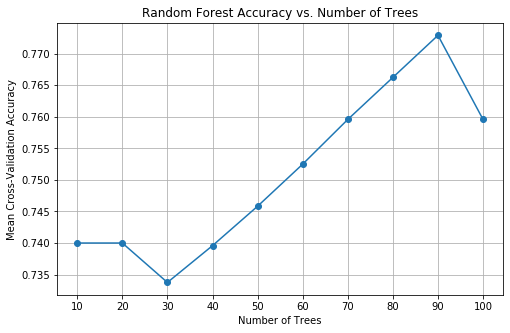

In [25]:
# PART G

# Number of trees to test
tree_counts = range(10, 101, 10)

# Store results
mean_accuracies = []
std_accuracies = []

# Evaluate each Random Forest model
for n_trees in tree_counts:

    rf = RandomForestClassifier(
        n_estimators=n_trees,
        random_state=1
    )

    scores = cross_val_score(
        rf,
        X,
        y,
        cv=kf,
        scoring='accuracy'
    )

    mean_accuracy = np.mean(scores)
    std_accuracy = np.std(scores)

    mean_accuracies.append(mean_accuracy)
    std_accuracies.append(std_accuracy)

    print(
        "Trees: {:3d} | Mean Accuracy: {:.4f} | Std: {:.4f}".format(
            n_trees,
            mean_accuracy,
            std_accuracy
        )
    )

# Find index of highest accuracy
best_index = np.argmax(mean_accuracies)

# Retrieve best number of trees and accuracy
best_trees = list(tree_counts)[best_index]
best_accuracy = mean_accuracies[best_index]

print("\nBEST RANDOM FOREST MODEL")
print("-----------------------------")

print("Number of trees:", best_trees)
print("Mean CV Accuracy:", round(best_accuracy, 4))

plt.figure(figsize=(8, 5))

plt.plot(
    list(tree_counts),
    mean_accuracies,
    marker='o'
)

plt.xlabel("Number of Trees")
plt.ylabel("Mean Cross-Validation Accuracy")

plt.title("Random Forest Accuracy vs. Number of Trees")

plt.xticks(list(tree_counts))
plt.grid(True)

plt.show()

Random Forest model fitted.
Number of trees: 100
Predictor raster dimensions: (1080, 1080, 10)
Total raster pixels: 1166400
Valid raster pixels: 1166400
Prediction map created.
Map dimensions: (1080, 1080)


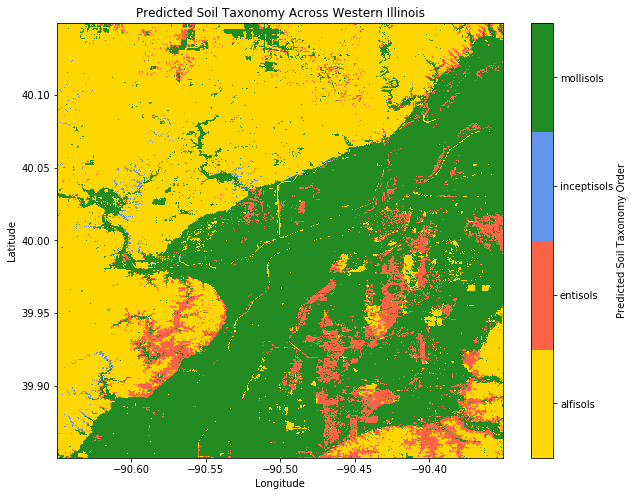

In [27]:
# PART H

# Create Random Forest with 100 trees
rf_map = RandomForestClassifier(
    n_estimators=100,
    random_state=1
)

# Fit model using all observations
rf_map.fit(X, y)

print("Random Forest model fitted.")
print("Number of trees:", rf_map.n_estimators)

# Store predictor raster arrays
raster_arrays = []

for name in predictor_names:

    raster = predictors.variables[name][:]

    # Convert masked values to NaN
    raster = np.ma.filled(raster, np.nan)

    raster_arrays.append(
        np.asarray(raster, dtype=float)
    )

# Stack into a 3D array:
# Rows x Columns x Predictors
predictor_stack = np.stack(
    raster_arrays,
    axis=-1
)

# Get raster dimensions
nrows, ncols, n_predictors = predictor_stack.shape

print("Predictor raster dimensions:", predictor_stack.shape)

# Flatten raster into 2D matrix
raster_pixels = predictor_stack.reshape(
    -1,
    n_predictors
)

# Identify pixels with valid values for every predictor
valid_pixels = np.isfinite(raster_pixels).all(axis=1)

print("Total raster pixels:", len(raster_pixels))
print("Valid raster pixels:", np.sum(valid_pixels))

# Initialize predictions with -1 for invalid pixels
predictions = np.full(
    len(raster_pixels),
    -1,
    dtype=int
)

# Predict valid pixels
predictions[valid_pixels] = rf_map.predict(
    raster_pixels[valid_pixels]
)

# Reshape predictions to original raster dimensions
prediction_map = predictions.reshape(
    nrows,
    ncols
)

print("Prediction map created.")
print("Map dimensions:", prediction_map.shape)

from matplotlib.colors import ListedColormap, BoundaryNorm

# Get coordinates
lat = predictors.variables['lat'][:]
lon = predictors.variables['lon'][:]

# Mask invalid pixels
prediction_map_masked = np.ma.masked_where(
    prediction_map == -1,
    prediction_map
)

# Define categorical colors
cmap = ListedColormap([
    'gold',
    'tomato',
    'cornflowerblue',
    'forestgreen'
])

norm = BoundaryNorm(
    [-0.5, 0.5, 1.5, 2.5, 3.5],
    cmap.N
)

plt.figure(figsize=(10, 8))

mesh = plt.pcolormesh(
    lon,
    lat,
    prediction_map_masked,
    cmap=cmap,
    norm=norm,
    shading='auto'
)

# Add colorbar with taxonomy labels
cbar = plt.colorbar(
    mesh,
    ticks=[0, 1, 2, 3]
)

cbar.ax.set_yticklabels(
    label_encoder.classes_
)

cbar.set_label('Predicted Soil Taxonomy Order')

plt.xlabel('Longitude')
plt.ylabel('Latitude')

plt.title(
    'Predicted Soil Taxonomy Across Western Illinois'
)

plt.show()

Number of original predictors: 10
Number of principal components needed: 6

Explained variance by each component:
PC1: 0.3610
PC2: 0.2638
PC3: 0.1847
PC4: 0.0635
PC5: 0.0566
PC6: 0.0466
PC7: 0.0173
PC8: 0.0047
PC9: 0.0016
PC10: 0.0003

Cumulative explained variance:
First 1 components: 0.3610
First 2 components: 0.6248
First 3 components: 0.8096
First 4 components: 0.8730
First 5 components: 0.9296
First 6 components: 0.9762
First 7 components: 0.9935
First 8 components: 0.9982
First 9 components: 0.9997
First 10 components: 1.0000

Variance explained by selected components: 0.9762


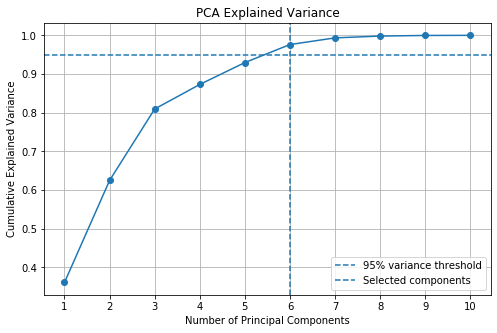

PCA + Random Forest pipeline created.
PCA + RANDOM FOREST RESULTS
--------------------------------
Fold 1: 0.8125
Fold 2: 0.6250
Fold 3: 0.5625
Fold 4: 0.8000
Fold 5: 0.8667
Fold 6: 0.6000
Fold 7: 0.8667
Fold 8: 0.5333
Fold 9: 0.7333
Fold 10: 0.6667

Mean CV Accuracy: 0.7067
Standard Deviation: 0.1193
MODEL COMPARISON
--------------------------------
Original Random Forest (100 trees): 0.7596
PCA + Random Forest:                 0.7067
Dataset closed successfully.


In [28]:
# PART I

# Standardize original predictors
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

# Perform PCA
pca = PCA()

X_pca = pca.fit_transform(X_scaled)

# Calculate explained variance
explained_variance = pca.explained_variance_ratio_

# Calculate cumulative explained variance
cumulative_variance = np.cumsum(explained_variance)

# Find components needed for 95% variance
n_components = np.argmax(
    cumulative_variance >= 0.95
) + 1

print("Number of original predictors:", X.shape[1])

print(
    "Number of principal components needed:",
    n_components
)

print("\nExplained variance by each component:")

for i, variance in enumerate(explained_variance):
    print("PC{}: {:.4f}".format(i + 1, variance))

print("\nCumulative explained variance:")

for i, variance in enumerate(cumulative_variance):
    print(
        "First {} components: {:.4f}".format(
            i + 1,
            variance
        )
    )

print(
    "\nVariance explained by selected components:",
    round(cumulative_variance[n_components - 1], 4)
)

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker='o'
)

plt.axhline(
    y=0.95,
    linestyle='--',
    label='95% variance threshold'
)

plt.axvline(
    x=n_components,
    linestyle='--',
    label='Selected components'
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")

plt.title("PCA Explained Variance")

plt.xticks(
    range(1, len(cumulative_variance) + 1)
)

plt.legend()
plt.grid(True)

plt.show()

# Create PCA + Random Forest pipeline
pca_rf = Pipeline([
    ('scaler', StandardScaler()),

    ('pca', PCA(n_components=0.95)),

    ('random_forest', RandomForestClassifier(
        n_estimators=100,
        random_state=1
    ))
])

print("PCA + Random Forest pipeline created.")

# Perform 10-fold cross-validation
scores = cross_val_score(
    pca_rf,
    X,
    y,
    cv=kf,
    scoring='accuracy'
)

# Print individual fold accuracies
print("PCA + RANDOM FOREST RESULTS")
print("--------------------------------")

for i, score in enumerate(scores):
    print("Fold {}: {:.4f}".format(i + 1, score))

# Calculate mean accuracy and standard deviation
mean_accuracy = np.mean(scores)
std_accuracy = np.std(scores)

print("\nMean CV Accuracy:", round(mean_accuracy, 4))
print("Standard Deviation:", round(std_accuracy, 4))

print("MODEL COMPARISON")
print("--------------------------------")

print("Original Random Forest (100 trees): 0.7596")

print(
    "PCA + Random Forest:                 {:.4f}".format(
        mean_accuracy
    )
)

rootgrp.close()

print("Dataset closed successfully.")